# Identity categorization · Figure 4B

按 Self 和 Other 分类时，Good-self 的漂移率是否高于 Bad-self 和 Good-other？起点是否偏向 Self？

运行环境为 Docker 镜像 `hcp4715/hddm:1.0.1` 的 Python 3 内核（CPU）。

## 1. 数据与编码

读取 [01_behavior.R](01_behavior.R) 导出的 `identity_hddm.csv`。试次按效价 `val` 和自我相关性 `id` 分组，RT 以秒计。`stim` 是正确边界，`response` 是由正确边界和原始正确性记录重建的选择。1 为 Self，0 为 Other。交叉表显示每种正确选项下的选择次数。

In [1]:
from pathlib import Path

import hddm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# 读取 Identity categorization 的试次输入表，指定条件列和结果目录。
data = hddm.load_csv("../data/derived/identity_hddm.csv")
results_dir = Path("../outputs/identity").resolve()
condition_columns = ["val", "id"]

# 显示样本计数与正确选项 × 实际选择的交叉表。
print(f"被试数：{data['subj_idx'].nunique()}，试次数：{len(data)}")
display(pd.crosstab(data["stim"], data["response"]))

被试数：41，试次数：14493


response,0,1
stim,,
0,6737,496
1,417,6843


## 2. 模型与先验

证据从 $X_0=a_j z_j$ 开始。被试 $j$ 在条件 $c$ 的有效漂移率为 $(2\,\mathrm{stim}-1)v_{jc}$。触碰上边界为 Self，触碰下边界为 Other。RT 是到达边界的时间与 $t_{jc}$ 之和。

`v` 和 `t` 随效价与自我相关性变化，`a` 和 `z` 在同一被试的各条件间共享。`split_param="v"` 按刺激翻转漂移方向，`drift_criterion=False`，`p_outlier=0`。

模型使用以下层级先验。Gamma 以均值和标准差表示，HalfNormal 括号内是尺度。

| 参数 | 组均值先验 | 被试层分布 | 被试层标准差先验 |
| --- | --- | --- | --- |
| 漂移率 `v` | Normal(2, SD 3) | Normal | HalfNormal(2) |
| 非决策时间 `t` | Gamma(0.40, SD 0.20) | Gamma | HalfNormal(1) |
| 边界间距 `a` | Gamma(1.50, SD 0.75) | Gamma | HalfNormal(2) |
| 起点 `logit(z)` | Normal(0, SD 0.50) | Normal | HalfNormal(0.05) |

[作者 Stimulus Coding Notebook](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Results/3_hddm/HDDM_MS_Rep_categ_stim.ipynb) · [归档最终模型](https://github.com/hcp4715/moralSelf_ddm/blob/master/2_confirm_study/Results/3_hddm/M_Categ_id_vtz_s_final)

In [2]:
# 构造刺激编码模型，使漂移率和非决策时间按试次条件变化。
def build_model(trials):
    return hddm.HDDMStimCoding(
        trials,
        include=("v", "a", "t", "z"),
        stim_col="stim",
        depends_on={"v": condition_columns, "t": condition_columns},
        split_param="v",
        drift_criterion=False,
        p_outlier=0.0,
    )

## 3. MCMC 采样

四条链独立初始化。每条采样 10,000 次，丢弃前 1,000 次，分别保存抽样链和模型。

In [3]:
# 定义独立链数、每链抽样次数和丢弃的初期样本数。
n_chains = 4
n_samples = 10_000
burn_in = 1_000

# 每条链单独设定随机种子、初始化和采样，并保存链文件和模型。
chains = []
for chain_id in range(1, n_chains + 1):
    np.random.seed(2020 + chain_id)
    model = build_model(data)
    model.find_starting_values()
    model.sample(
        n_samples, burn=burn_in,
        db="pickle", dbname=str(results_dir / f"chain_{chain_id}.db"),
    )
    model.save(str(results_dir / f"chain_{chain_id}.model"))
    chains.append(model)

Chain 1 completed


Chain 2 completed


Chain 4 completed


Chain 3 completed


## 4. 链诊断表与轨迹图

R̂ 表覆盖全部随机节点。轨迹图展示 Good-self 条件的 `v`、`t` 及共享的 `a`、`z`。

parameter
a_subj.7327                1.001966
a_subj.7312                1.001337
a_subj.7331                1.001160
a_subj.7321                1.000968
z_subj_trans.7306          1.000783
v_subj(Self.Good).7312     1.000764
a_subj.7318                1.000731
t_subj(Other.Good).7318    1.000727
t_subj(Self.Bad).7312      1.000615
v_subj(Self.Good).7339     1.000577
Name: R_hat, dtype: float64

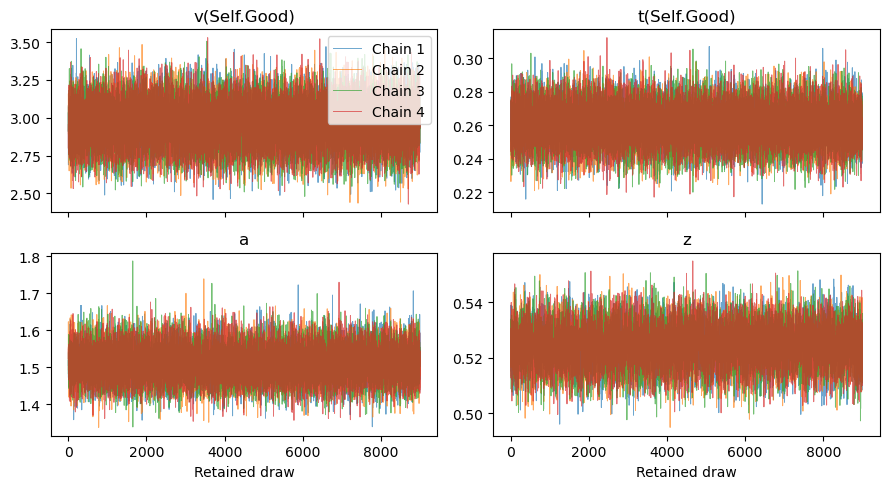

In [4]:
# 生成链诊断表，按 R̂ 从大到小列出各随机节点。
rhat = (
    pd.Series(hddm.analyze.gelman_rubin(chains), name="R_hat")
    .rename_axis("parameter")
    .sort_values(ascending=False)
)
display(rhat.head(10))

# 绘制 v、t、a、z 的轨迹图，同一参数的各条链叠画在一个子图中。
trace_nodes = ["v(Self.Good)", "t(Self.Good)", "a", "z"]
trace_figure, axes = plt.subplots(2, 2, figsize=(9, 5), sharex=True)

for ax, node in zip(axes.flat, trace_nodes):
    for chain_id, model in enumerate(chains, start=1):
        ax.plot(model[node].trace()[:], lw=0.7, alpha=0.65, label=f"Chain {chain_id}")
    ax.set_title(node)

axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("Retained draw")
trace_figure.tight_layout()
plt.show()

## 5. 后验预测检查表

每次用同一后验样本模拟全部试次。分条件对照 Self 选择比例，以及两种选择各自的 RT 第 10、50、90 百分位数。预测区间取模拟统计量的第 2.5 和 97.5 百分位数。

In [5]:
# 从同一后验抽样模拟一整份试次，保留每个模拟试次的条件标签。
def simulate_trials(model, draw):
    # 所有随机节点取同一次抽样，模拟结束后恢复模型状态。
    parameters = model.get_stochastics()["node"]
    original_values = [node.value for node in parameters]
    parts = []

    try:
        for node in parameters:
            node.value = node.trace()[draw]

        # 逐个观测节点生成选择和 RT，拼回原试次的条件标签。
        for _, observed in model.iter_observeds():
            node = observed["node"]
            conditions = model.data.loc[node.value.index, condition_columns]
            simulated = node.random()
            parts.append(pd.concat([
                conditions.reset_index(drop=True),
                simulated.reset_index(drop=True),
            ], axis=1))
    finally:
        for node, value in zip(parameters, original_values):
            node.value = value

    return pd.concat(parts, ignore_index=True)


# 按条件算 Self 选择比例，并按实际选择分别算 RT 分位数。
def ppc_statistics(trials):
    p_self = trials.groupby(condition_columns)["response"].mean().rename("p_self")
    rt_quantiles = (
        trials.assign(rt=trials["rt"].abs())
        .groupby(condition_columns + ["response"])["rt"]
        .quantile([0.10, 0.50, 0.90])
        .unstack(["response", -1])
    )
    rt_quantiles.columns = [
        f"rt_q{100 * q:.0f}_response{int(response)}"
        for response, q in rt_quantiles.columns
    ]
    return p_self.to_frame().join(rt_quantiles).rename_axis(columns="statistic").stack()

In [6]:
# 从每条链等量抽取后验样本并汇总各份模拟试次。
np.random.seed(2030)
predictions_per_chain = 25

simulated_statistics = []
for model in chains:
    n_draws = len(model["z"].trace())
    draws = np.random.choice(n_draws, size=predictions_per_chain, replace=False)
    for draw in draws:
        simulated_statistics.append(ppc_statistics(simulate_trials(model, draw)))

# 生成后验预测检查表，对照观测统计量、预测中位数和 95% 预测区间。
predicted = pd.concat(simulated_statistics, axis=1).T
ppc = pd.DataFrame({
    "observed": ppc_statistics(data),
    "predicted_median": predicted.median(),
    "predicted_q025": predicted.quantile(0.025),
    "predicted_q975": predicted.quantile(0.975),
    "n_predictions": predicted.count(),
}).reset_index()

display(ppc.head(14))

,val,id,statistic,observed,predicted_median,predicted_q025,predicted_q975,n_predictions
0,Bad,Other,p_self,0.057915,0.039713,0.031702,0.059294,100
1,Bad,Other,rt_q10_response0,0.367200,0.345541,0.327421,0.359612,100
2,Bad,Other,rt_q50_response0,0.495750,0.481453,0.456728,0.507370,100
3,Bad,Other,rt_q90_response0,0.664850,0.750492,0.699455,0.838534,100
4,Bad,Other,rt_q10_response1,0.313790,0.309664,0.282379,0.342942,100
5,Bad,Other,rt_q50_response1,0.427850,0.472983,0.422517,0.536798,100
6,Bad,Other,rt_q90_response1,0.703890,0.867841,0.742576,1.084785,100
7,Bad,Self,p_self,0.922886,0.955915,0.921697,0.974323,100
8,Bad,Self,rt_q10_response0,0.317200,0.310240,0.280840,0.332822,100
9,Bad,Self,rt_q50_response0,0.508200,0.488386,0.429686,0.589604,100


## 6. 后验对比表

对同一次抽样中的组级参数做减法，汇总两个漂移率对比和 `z − 0.5` 的均值、95% 可信区间和方向概率。后者大于零表示起点偏向 Self。论文报告的方向概率单列。 [Hu et al. (2020)](https://doi.org/10.1525/collabra.301)

In [7]:
# 提取四个条件的组级 v，以及共享起点 z 的抽样。
drift_nodes = {
    "Good-self":  "v(Self.Good)",
    "Bad-self":   "v(Self.Bad)",
    "Good-other": "v(Other.Good)",
    "Bad-other":  "v(Other.Bad)",
}
drift_draws = pd.concat(
    [
        pd.DataFrame({
            condition: model[node].trace()[:]
            for condition, node in drift_nodes.items()
        })
        for model in chains
    ],
    ignore_index=True,
)
z_draws = np.concatenate([model["z"].trace()[:] for model in chains])

# 在同一次抽样内相减，保留两个漂移率对比和起点相对 0.5 的偏移。
differences = pd.DataFrame({
    "v(Good-self) − v(Bad-self)": drift_draws["Good-self"] - drift_draws["Bad-self"],
    "v(Good-self) − v(Good-other)": drift_draws["Good-self"] - drift_draws["Good-other"],
    "z − 0.5": z_draws - 0.5,
})
# 生成后验对比表，汇总差值、95% 可信区间和方向概率。
posterior_contrasts = pd.DataFrame({
    "mean_difference": differences.mean(),
    "q025": differences.quantile(0.025),
    "q975": differences.quantile(0.975),
    "P(difference > 0)": differences.gt(0).mean(),
    "paper_probability": ['0.99', '>0.996', '1.00'],
}).rename_axis("contrast")

display(posterior_contrasts)

,mean_difference,q025,q975,P(difference > 0),paper_probability
contrast,,,,,
v(Good-self) − v(Bad-self),0.508991,0.138931,0.878260,0.996389,0.99
v(Good-self) − v(Good-other),0.510368,0.132069,0.887298,0.995444,>0.996
z − 0.5,0.024323,0.010535,0.037880,0.999583,1.00


## 7. 绘制 Figure 4B

使用与对比表相同的抽样绘制四个条件的组级漂移率后验密度。

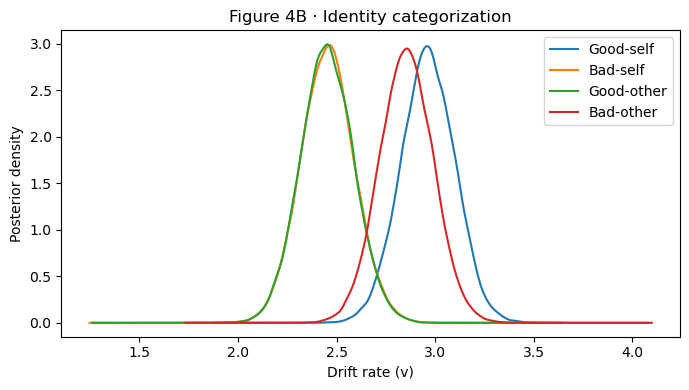

In [8]:
# 绘制 Figure 4B，叠加四个条件的组级漂移率后验密度。
ax = drift_draws.plot.kde(ind=300, figsize=(7, 4))
ax.set(
    title="Figure 4B · Identity categorization",
    xlabel="Drift rate (v)",
    ylabel="Posterior density",
)
figure_4b = ax.figure
figure_4b.tight_layout()
plt.show()

## 8. 导出表和图

链诊断表、后验预测检查表、后验对比表、Figure 4B 和链轨迹图保存到 `outputs/identity/`。

In [9]:
# 保存链诊断、后验预测检查和后验对比三张 CSV 表。
rhat.to_csv(results_dir / "rhat.csv")
ppc.to_csv(results_dir / "ppc.csv", index=False)
posterior_contrasts.to_csv(results_dir / "posterior_contrasts.csv")

# 保存 Figure 4B 和链轨迹图的 PDF。
figure_4b.savefig(results_dir / "Figure_4B.pdf")
trace_figure.savefig(results_dir / "trace_diagnostics.pdf")